In [2]:


import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.estimators import BayesianEstimator
from pgmpy.inference import VariableElimination

C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\ASUS\AppData\Roaming\Python\Python313\site-packages\pgmpy\estimators\__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
df = pd.read_csv("heart_disease.csv")

df.columns = df.columns.str.strip()

print(df.head())
print(df.columns.tolist())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  condition  
0   1     0          0  
1   2     0          0  
2   0     0          0  
3   1     0          1  
4   0     0          0  
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'condition']


In [4]:
# Replace missing values
df.replace('?', np.nan, inplace=True)

# Identify target column
target_names = ['target', 'condition', 'num', 'HeartDisease', 'heartdisease']

target_col = next(
    (col for col in df.columns if col.lower() in
     [name.lower() for name in target_names]),
    None
)

if target_col is None:
    raise ValueError("Target column not found. Check df.columns.")

df.rename(columns={target_col: 'target'}, inplace=True)

# Convert columns to numeric
df = df.apply(pd.to_numeric, errors='coerce')

# Remove rows with missing target
df.dropna(subset=['target'], inplace=True)

# Fill missing values
df = df.fillna(df.mode().iloc[0])

print("Target column:", 'target')
print(df.head())

Target column: target
   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0   69    1   0       160   234    1        2      131      0      0.1      1   
1   69    0   0       140   239    0        0      151      0      1.8      0   
2   66    0   0       150   226    0        0      114      0      2.6      2   
3   65    1   0       138   282    1        2      174      0      1.4      1   
4   64    1   0       110   211    0        2      144      1      1.8      1   

   ca  thal  target  
0   1     0       0  
1   2     0       0  
2   0     0       0  
3   1     0       1  
4   0     0       0  


In [5]:
continuous = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']

for col in continuous:
    if col in df.columns:
        df[col] = pd.cut(
            df[col],
            bins=3,
            labels=False,
            duplicates='drop'
        )

print(df.head())

   age  sex  cp  trestbps  chol  fbs  restecg  thalach  exang  oldpeak  slope  \
0    2    1   0         1     0    1        2        1      0        0      1   
1    2    0   0         1     0    0        0        1      0        0      0   
2    2    0   0         1     0    0        0        0      0        1      2   
3    2    1   0         1     1    1        2        2      0        0      1   
4    2    1   0         0     0    0        2        1      1        0      1   

   ca  thal  target  
0   1     0       0  
1   2     0       0  
2   0     0       0  
3   1     0       1  
4   0     0       0  


In [6]:
X = df.drop('target', axis=1)
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

train_data = X_train.copy()
train_data['target'] = y_train

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 237
Testing records: 60


In [7]:
edges = [(col, 'target') for col in X.columns]

model = DiscreteBayesianNetwork(edges)

model.add_cpds(*BayesianEstimator(
    model,
    train_data
).get_parameters(prior_type='BDeu'))

print("Bayesian Network created successfully!")

C:\Users\ASUS\AppData\Local\Temp\ipykernel_23532\3477356697.py:5: FutureWarning: `pgmpy.estimators.BayesianEstimator` is deprecated and will be removed in v1.3.0. Please use `pgmpy.parameter_estimator.DiscreteBayesianEstimator` instead.
  model.add_cpds(*BayesianEstimator(


Bayesian Network created successfully!


In [8]:
infer = VariableElimination(model)

predictions = []

for _, row in X_test.iterrows():
    result = infer.map_query(
        variables=['target'],
        evidence=row.to_dict(),
        show_progress=False
    )

    predictions.append(result['target'])

accuracy = accuracy_score(y_test, predictions)

print("Actual values:", list(y_test))
print("Predicted values:", predictions)
print("Accuracy:", accuracy * 100, "%")

Actual values: [0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1]
Predicted values: [np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(0), np.int64(1), np.int64(0), np.int64(0), np.int64(0)]
Accur

In [9]:
patient = X_test.iloc[0].to_dict()

result = infer.map_query(
    variables=['target'],
    evidence=patient,
    show_progress=False
)

print("Patient Details:")
print(patient)

print("Heart Disease Prediction:", result['target'])

Patient Details:
{'age': 0, 'sex': 0, 'cp': 3, 'trestbps': 1, 'chol': 0, 'fbs': 0, 'restecg': 0, 'thalach': 2, 'exang': 0, 'oldpeak': 0, 'slope': 0, 'ca': 0, 'thal': 0}
Heart Disease Prediction: 0


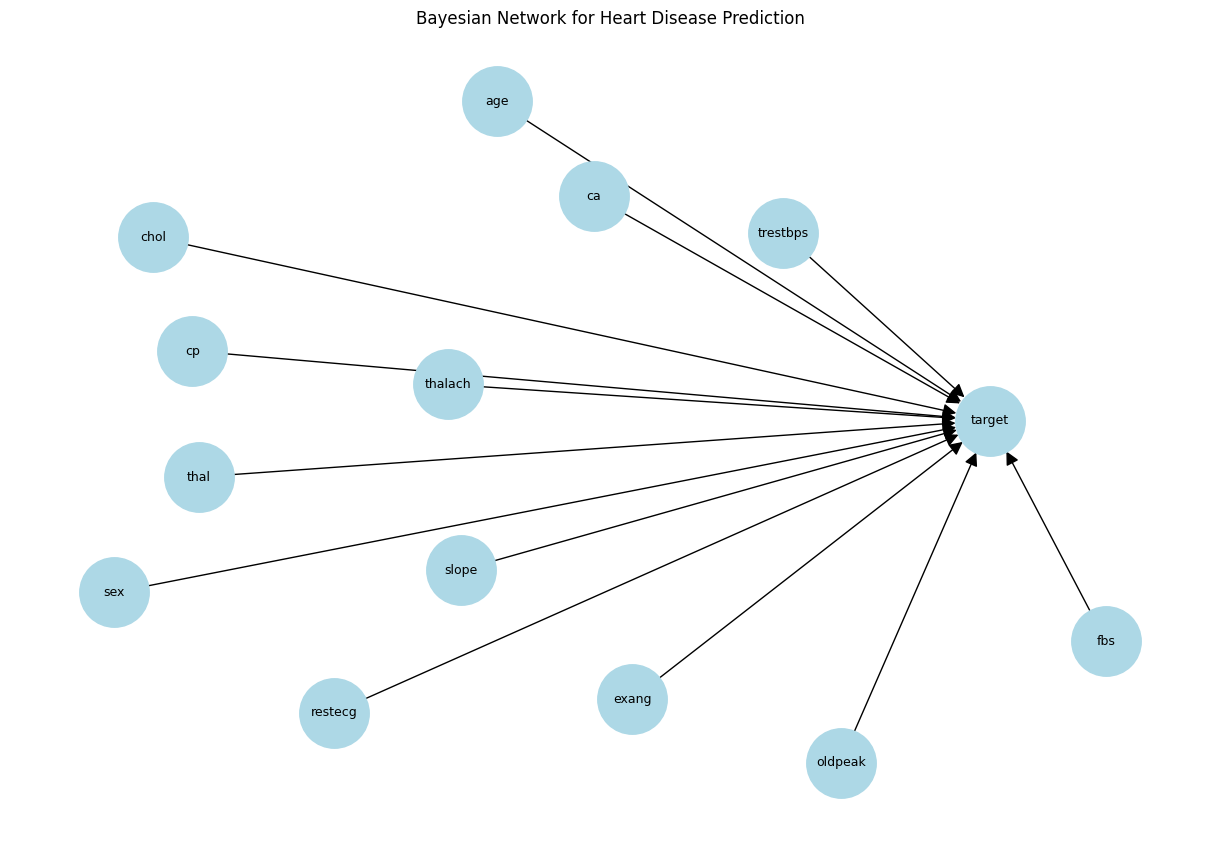

In [10]:
import networkx as nx
import matplotlib.pyplot as plt

G = nx.DiGraph()
G.add_edges_from(edges)

plt.figure(figsize=(12, 8))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G, pos,
    with_labels=True,
    node_color='lightblue',
    node_size=2500,
    font_size=9,
    arrows=True,
    arrowsize=20
)

plt.title("Bayesian Network for Heart Disease Prediction")
plt.show()